# Pipeline completo: recomendador de libros con IHDT

5 etapas: adquisición, preprocesamiento, división y grafo, entrenamiento y evaluación.


## 0. Preparación

In [ ]:
import os, subprocess, sys

REPO_URL = "https://github.com/FreddyForero1988/Proyecto-Final-Ap_Deep_Learning.git"


# 2. Clonar y entrar a la carpeta del proyecto (si no estás ya dentro)
if not os.path.exists("src"):
    repo_dir = REPO_URL.rstrip("/").split("/")[-1]
    if repo_dir.endswith(".git"):
        repo_dir = repo_dir[:-4]
    if not os.path.exists(repo_dir):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(repo_dir)
    # Si subiste la carpeta completa a GitHub, el proyecto queda en una subcarpeta
    if not os.path.exists("src"):
        subs = [d for d in os.listdir(".") if os.path.exists(os.path.join(d, "src"))]
        if not subs:
            raise FileNotFoundError("No encuentro la carpeta 'src' en el repositorio. "
                                    "Revisa qué archivos subiste a GitHub.")
        os.chdir(subs[0])

print("Carpeta de trabajo:", os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

Carpeta de trabajo: /content/Proyecto-Final-Ap_Deep_Learning


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [ ]:
import torch
print("GPU disponible:", torch.cuda.is_available())

GPU disponible: True


## 1. Parámetros

Los valores por defecto están en `src/config.py`. Modifica aquí lo que necesites.

In [ ]:
from src.config import Config

cfg = Config()
# Prueba rápida (descomenta para comprobar que todo corre en pocos minutos):
# cfg.user_frac, cfg.epochs = 0.05, 2
cfg.batch_size = 16384
cfg.epochs = 30
cfg

Config(pos_threshold=4, min_pos_per_user=5, drop_genres=('fiction',), genres_per_book=5, max_authors_per_book=3, user_frac=1.0, test_frac=0.1, val_frac=0.1, seed=42, dim=64, n_layers=3, dropout=0.1, lr=0.001, weight_decay=1e-05, batch_size=16384, epochs=30, patience=10, topk=20, use_genres=True, use_authors=True, use_interaction=True)

## 2. Etapas 1 a 3: adquisición, preprocesamiento, división y grafo

In [ ]:
from src.data import prepare_data

data = prepare_data(cfg)
print(f"Lectores: {data.n_users} | libros: {data.n_items}")
print(f"train/val/test: {len(data.train)}/{len(data.val)}/{len(data.test)}")
print(f"géneros: {len(data.genre_vocab)} | autores: {len(data.author_vocab)}")
data.items.head()

Descargando ratings.csv ...
Descargando books.csv ...
Descargando book_tags.csv ...
Descargando tags.csv ...
Lectores: 53366 | libros: 10000
train/val/test: 3338413/371299/412295
géneros: 36 | autores: 5469


,item_idx,book_id,title,genres,authors
0,0,1,"The Hunger Games (The Hunger Games, #1)",young-adult|dystopian|science-fiction|fantasy|...,Suzanne Collins
1,1,2,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy|young-adult|children|adventure|classics,J.K. Rowling|Mary GrandPré
2,2,3,"Twilight (Twilight, #1)",young-adult|paranormal|fantasy|paranormal-roma...,Stephenie Meyer
3,3,4,To Kill a Mockingbird,classics|historical-fiction|young-adult|litera...,Harper Lee
4,4,5,The Great Gatsby,classics|literary-fiction|historical-fiction|r...,F. Scott Fitzgerald


## 3. Etapas 4 y 5: entrenamiento y evaluación

Entrena y evalúa popularidad, MF-BPR, LightGCN e IHDT.

In [ ]:
from src.train import run

results, table = run(["popularity", "mf", "lightgcn", "ihdt"], cfg)
table.round(4)

Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 53366 | libros: 10000 | train/val/test: 3338413/371299/412295


/content/Proyecto-Final-Ap_Deep_Learning/src/data.py:185: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(torch.stack([rows, cols]), vals, shape).coalesce().to(device)


[popularity] TEST {'precision@20': 0.0298, 'recall@20': 0.0774, 'ndcg@20': 0.0674, 'hr@20': 0.4054}
[mf] época   1 | pérdida 0.6937 | val recall@20 0.0075 | 2s
[mf] época   2 | pérdida 0.6872 | val recall@20 0.0740 | 4s
[mf] época   3 | pérdida 0.6105 | val recall@20 0.0783 | 5s
[mf] época   4 | pérdida 0.4829 | val recall@20 0.0802 | 7s
[mf] época   5 | pérdida 0.4478 | val recall@20 0.0823 | 9s
[mf] época   6 | pérdida 0.4353 | val recall@20 0.0853 | 10s
[mf] época   7 | pérdida 0.4241 | val recall@20 0.0886 | 12s
[mf] época   8 | pérdida 0.4143 | val recall@20 0.0916 | 14s
[mf] época   9 | pérdida 0.4062 | val recall@20 0.0950 | 16s
[mf] época  10 | pérdida 0.4000 | val recall@20 0.0975 | 17s
[mf] época  11 | pérdida 0.3954 | val recall@20 0.0998 | 19s
[mf] época  12 | pérdida 0.3921 | val recall@20 0.1019 | 21s
[mf] época  13 | pérdida 0.3896 | val recall@20 0.1037 | 22s
[mf] época  14 | pérdida 0.3876 | val recall@20 0.1047 | 24s
[mf] época  15 | pérdida 0.3861 | val recall@20 0.1

,precision@20,recall@20,ndcg@20,hr@20
popularity,0.0298,0.0774,0.0674,0.4054
mf,0.0432,0.1112,0.0975,0.5334
lightgcn,0.0300,0.0779,0.0675,0.4076
ihdt,0.0499,0.1294,0.1027,0.5943


# IHDT completo

In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.use_genres = False

run(["ihdt"], cfg)

Dispositivo: cuda
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.3751 | val recall@20 0.0696 | 3s
[ihdt] época   2 | pérdida 0.2487 | val recall@20 0.0899 | 7s
[ihdt] época   3 | pérdida 0.2221 | val recall@20 0.0956 | 10s
[ihdt] época   4 | pérdida 0.2141 | val recall@20 0.0984 | 14s
[ihdt] época   5 | pérdida 0.2084 | val recall@20 0.0987 | 18s
[ihdt] TEST {'precision@20': 0.039, 'recall@20': 0.1017, 'ndcg@20': 0.0783, 'hr@20': 0.5092}


({'_config': {'pos_threshold': 4,
   'min_pos_per_user': 5,
   'drop_genres': ('fiction',),
   'genres_per_book': 5,
   'max_authors_per_book': 3,
   'user_frac': 0.1,
   'test_frac': 0.1,
   'val_frac': 0.1,
   'seed': 42,
   'dim': 64,
   'n_layers': 3,
   'dropout': 0.1,
   'lr': 0.001,
   'weight_decay': 1e-05,
   'batch_size': 4096,
   'epochs': 5,
   'patience': 10,
   'topk': 20,
   'use_genres': False,
   'use_authors': True,
   'use_interaction': True},
  'popularity': {'val': {'precision@20': 0.026233932083167624,
    'recall@20': 0.07608796163186611,
    'ndcg@20': 0.062093787852181746,
    'hr@20': 0.3743019900311059},
   'test': {'precision@20': 0.0297951883932499,
    'recall@20': 0.07744797597701496,
    'ndcg@20': 0.06743012699449866,
    'hr@20': 0.4054079376381966}},
  'mf': {'val': {'precision@20': 0.038117903620881424,
    'recall@20': 0.10950682471771807,
    'ndcg@20': 0.08952541735175577,
    'hr@20': 0.49801371659858334},
   'test': {'precision@20': 0.0431913589

# Sin autores




In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.use_authors = False

results_no_authors, table_no_authors = run(
    ["ihdt"],
    cfg
)

display(table_no_authors)

Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.3478 | val recall@20 0.0655 | 3s
[ihdt] época   2 | pérdida 0.2351 | val recall@20 0.0880 | 7s
[ihdt] época   3 | pérdida 0.2171 | val recall@20 0.0942 | 10s
[ihdt] época   4 | pérdida 0.2105 | val recall@20 0.0970 | 14s
[ihdt] época   5 | pérdida 0.2050 | val recall@20 0.0986 | 17s
[ihdt] TEST {'precision@20': 0.0385, 'recall@20': 0.1009, 'ndcg@20': 0.0773, 'hr@20': 0.5013}


,precision@20,recall@20,ndcg@20,hr@20
ihdt,0.03854,0.100904,0.077281,0.501312


# SIn generos

In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.use_genres = False

results_no_genres, table_no_genres = run(
    ["ihdt"],
    cfg
)

display(table_no_genres)

Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.3751 | val recall@20 0.0698 | 3s
[ihdt] época   2 | pérdida 0.2485 | val recall@20 0.0900 | 7s
[ihdt] época   3 | pérdida 0.2220 | val recall@20 0.0962 | 10s
[ihdt] época   4 | pérdida 0.2140 | val recall@20 0.0973 | 14s
[ihdt] época   5 | pérdida 0.2084 | val recall@20 0.0985 | 17s
[ihdt] TEST {'precision@20': 0.0389, 'recall@20': 0.1015, 'ndcg@20': 0.078, 'hr@20': 0.5073}


,precision@20,recall@20,ndcg@20,hr@20
ihdt,0.038877,0.101471,0.077955,0.507309


# Sin interacción

In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.use_interaction = False

results_no_interaction, table_no_interaction = run(
    ["ihdt"],
    cfg
)

display(table_no_interaction)


Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.3516 | val recall@20 0.0722 | 3s
[ihdt] época   2 | pérdida 0.2416 | val recall@20 0.0867 | 6s
[ihdt] época   3 | pérdida 0.2253 | val recall@20 0.0937 | 8s
[ihdt] época   4 | pérdida 0.2180 | val recall@20 0.0992 | 11s
[ihdt] época   5 | pérdida 0.2125 | val recall@20 0.0995 | 14s
[ihdt] TEST {'precision@20': 0.0391, 'recall@20': 0.1016, 'ndcg@20': 0.0787, 'hr@20': 0.5081}


,precision@20,recall@20,ndcg@20,hr@20
ihdt,0.039093,0.101566,0.078704,0.508058


# Tabla comparativa

In [ ]:
import pandas as pd

ablation = pd.DataFrame([
    {
        "Experimento":"Sin géneros",
        **table_no_genres.iloc[0].to_dict()
    },
    {
        "Experimento":"Sin autores",
        **table_no_authors.iloc[0].to_dict()
    },
    {
        "Experimento":"Sin interacción",
        **table_no_interaction.iloc[0].to_dict()
    }
])

ablation

,Experimento,precision@20,recall@20,ndcg@20,hr@20
0,Sin géneros,0.038877,0.101471,0.077955,0.507309
1,Sin autores,0.038540,0.100904,0.077281,0.501312
2,Sin interacción,0.039093,0.101566,0.078704,0.508058


# Experimento Baseline

In [ ]:
import pandas as pd

hp_results = []

In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.dim = 64

_, table = run(
    ["ihdt"],
    cfg
)

hp_results.append(
    {
        "Experimento":"dim=64",
        **table.iloc[0].to_dict()
    }
)

table

Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.3446 | val recall@20 0.0719 | 4s
[ihdt] época   2 | pérdida 0.2340 | val recall@20 0.0885 | 8s
[ihdt] época   3 | pérdida 0.2173 | val recall@20 0.0961 | 11s
[ihdt] época   4 | pérdida 0.2112 | val recall@20 0.0989 | 15s
[ihdt] época   5 | pérdida 0.2061 | val recall@20 0.1012 | 18s
[ihdt] TEST {'precision@20': 0.0396, 'recall@20': 0.103, 'ndcg@20': 0.0791, 'hr@20': 0.5152}


,precision@20,recall@20,ndcg@20,hr@20
ihdt,0.03958,0.103018,0.079125,0.51518


# Experimento HP1

In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.dim = 32

_, table = run(
    ["ihdt"],
    cfg
)

hp_results.append(
    {
        "Experimento":"dim=32",
        **table.iloc[0].to_dict()
    }
)

table

Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.4140 | val recall@20 0.0546 | 2s
[ihdt] época   2 | pérdida 0.2554 | val recall@20 0.0750 | 5s
[ihdt] época   3 | pérdida 0.2324 | val recall@20 0.0868 | 7s
[ihdt] época   4 | pérdida 0.2216 | val recall@20 0.0901 | 9s
[ihdt] época   5 | pérdida 0.2155 | val recall@20 0.0938 | 12s
[ihdt] TEST {'precision@20': 0.0362, 'recall@20': 0.0945, 'ndcg@20': 0.0722, 'hr@20': 0.4833}


,precision@20,recall@20,ndcg@20,hr@20
ihdt,0.036226,0.094498,0.072248,0.483321


# Experimento HP2

In [ ]:
cfg = Config()

cfg.user_frac = 0.10
cfg.epochs = 5

cfg.dim = 128

_, table = run(
    ["ihdt"],
    cfg
)

hp_results.append(
    {
        "Experimento":"dim=128",
        **table.iloc[0].to_dict()
    }
)

table

Dispositivo: cuda
Usando datos procesados en caché (data/processed y data/splits)
Lectores: 5336 | libros: 10000 | train/val/test: 333650/37121/41187
[ihdt] época   1 | pérdida 0.3026 | val recall@20 0.0928 | 6s
[ihdt] época   2 | pérdida 0.2181 | val recall@20 0.1013 | 11s
[ihdt] época   3 | pérdida 0.2078 | val recall@20 0.1027 | 17s
[ihdt] época   4 | pérdida 0.2033 | val recall@20 0.1044 | 23s
[ihdt] época   5 | pérdida 0.1992 | val recall@20 0.1075 | 29s
[ihdt] TEST {'precision@20': 0.0419, 'recall@20': 0.1097, 'ndcg@20': 0.0856, 'hr@20': 0.5343}


,precision@20,recall@20,ndcg@20,hr@20
ihdt,0.041942,0.109672,0.085637,0.534295


## Tabla final

In [ ]:
hp_df = pd.DataFrame(hp_results)

hp_df

,Experimento,precision@20,recall@20,ndcg@20,hr@20
0,dim=64,0.039580,0.103018,0.079125,0.515180
1,dim=32,0.036226,0.094498,0.072248,0.483321
2,dim=128,0.041942,0.109672,0.085637,0.534295


## 4. Curvas de validación

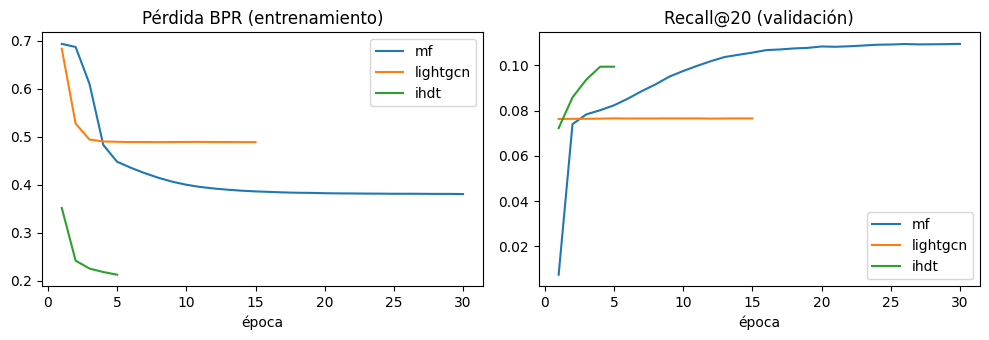

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from src.config import RESULTS_DIR

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name in ["mf", "lightgcn", "ihdt"]:
    h = pd.read_csv(RESULTS_DIR / f"history_{name}.csv")
    ax[0].plot(h["epoch"], h["loss"], label=name)
    ax[1].plot(h["epoch"], h[f"recall@{cfg.topk}"], label=name)
ax[0].set_title("Pérdida BPR (entrenamiento)"); ax[1].set_title(f"Recall@{cfg.topk} (validación)")
for a in ax: a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
import shutil
from google.colab import files
from src.config import RESULTS_DIR

shutil.make_archive("results", "zip", RESULTS_DIR)
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>